# 05 · Risk over time and the SPY trend filter

Notebook 04 asked how much each strategy made by the end. This one asks **what the path was like**,
and whether a simple market switch makes the bad stretches shallower.

**The trend filter, fixed before any result was seen:**
- At each month-end, compare SPY's close with the average of its **last 10 month-end closes** (about
  its 200-day average). That's a published convention (Faber, 2007), not a setting tuned here.
- **Above it:** invest as usual. **Below it:** sell everything at the next open (costs charged) and
  hold cash, earning the Fed Funds rate, until SPY is back above. Then every part of the portfolio
  buys that month's picks.
- Every strategy from notebook 04 gets a filtered version, plus SPY itself. The table shows the
  pre-declared strategies in full, and the filter's **average** effect over all of them. No filtered
  strategy is picked from the list.

**Windows.** Models and rules are compared only on the months they share: 2020–2022 and the test
years (decisions from January 2023), each starting from $10,000. The rules can also be run from
2010, so they get a separate chart. The rule chosen in notebook 04 was picked on 2010–2022, so only
its test years are clean.

> Numbers are a **preview** until the Alpha Vantage download of delisted companies is finished.

In [1]:
import pandas as pd

from sp500_momentum import backtest as bt
from sp500_momentum import config, nb, plots
from sp500_momentum.modeling.models import SPECS

nb.setup()  # caps table output, silences info logs, applies the chart style (see sp500_momentum/nb.py)

## 1. The trend signal

The months the filter would have kept out of the market (decisions; the trade is at the next open):

In [2]:
prices = pd.read_parquet(config.MONTHLY_PRICES)
panel = bt.add_rule_preds(pd.read_parquet(config.MONTHLY_PANEL))
values = bt.value_matrix(prices)
bench = bt.benchmark_returns(panel, values)
rf = bt.risk_free(pd.read_csv(config.FRED_DIR / "FEDFUNDS.csv"))
invested = bt.trend_signal(prices)
cash = bt.cash_returns(rf, values.index)

periods = {
    "2010–2022": (config.SPLIT["train"][0], config.RULE_CHECK_FROM),
    "2020–2022": (config.SPLIT["validation"][0], config.RULE_CHECK_FROM),
    "test years": (config.RULE_CHECK_FROM, None),
}
for p, (a, b) in periods.items():
    off = bt.off_decisions(invested, a, b)
    n = len(bt.window(bench, a, b))
    print(f"{p}: out at {len(off)} of {n} decisions: {', '.join(map(str, off)) or 'none'}")

2010–2022: out at 27 of 156 decisions: 2010-06, 2010-08, 2011-08, 2011-09, 2011-10, 2011-11, 2011-12, 2015-08, 2015-09, 2016-01, 2016-02, 2018-10, 2018-12, 2019-01, 2019-05, 2020-02, 2020-03, 2020-04, 2022-02, 2022-04, 2022-05, 2022-06, 2022-07, 2022-08, 2022-09, 2022-10, 2022-12
2020–2022: out at 12 of 36 decisions: 2020-02, 2020-03, 2020-04, 2022-02, 2022-04, 2022-05, 2022-06, 2022-07, 2022-08, 2022-09, 2022-10, 2022-12
test years: out at 4 of 45 decisions: 2023-10, 2025-03, 2025-04, 2026-03


## 2. Every strategy, with and without the filter

The 121 strategies from notebook 04 (8 models and 2 rules × top 1/5/10 × 4 versions, plus the rule
chosen there), each also run with the filter, and SPY filtered. Every result is saved to
`reports/strategies_trend_2020_2026.csv`. This takes a couple of minutes.

In [3]:
scores = pd.read_parquet(config.MODEL_SCORES)
comparison = pd.read_csv(config.REPORTS_DIR / "model_comparison.csv")
headline = comparison.loc[comparison["headline"], "model"].iloc[0]
models = [c for c in scores.columns if c not in ("date", "ticker", "price_ticker", "period")]
signals = {m: m for m in models} | {"mom_1m": "ret_1m", "mom_6m": "ret_6m"}
features = pd.read_parquet(
    config.FEATURES_TABLE, columns=["date", "price_ticker", config.INVERSE_VOL_FEATURE]
)
vol = bt.volatility_lookup(features, config.INVERSE_VOL_FEATURE)
scored = bt.merge_scores(panel, scores, models)

plain_r, plain_c = bt.run_strategies(scored, values, signals, vol)
trend_r, trend_c = bt.run_strategies(
    scored, values, signals, vol, invested=invested, cash_return=cash
)

# the rule chosen in notebook 04, re-derived the same way (best Sharpe on decisions 2010-2022)
grid_r, grid_c = bt.run_grid(panel, values, config.HOLD_MONTHS)
best, _, _ = bt.selection_check(grid_r, bench, rf, grid_c, config.RULE_CHECK_FROM)
cell = bt.parse_cell(best)
chosen_picks = bt.picks_by_month(panel, bt.rule_name(cell["lookback"], cell["top_n"]))
chosen_trend = bt.simulate(chosen_picks, values, cell["hold"], invested=invested, cash_return=cash)
spy_trend = bt.simulate(
    {m: ["SPY"] for m in chosen_picks}, values, 1, invested=invested, cash_return=cash
)

extra_r = pd.DataFrame(
    {
        "chosen_rule": grid_r[best],
        "chosen_rule_trend": chosen_trend["ret"],
        "spy_trend": spy_trend["ret"],
    }
)
extra_c = pd.DataFrame(
    {
        "chosen_rule": grid_c[best],
        "chosen_rule_trend": chosen_trend["cost"],
        "spy_trend": spy_trend["cost"],
    }
)
rets = pd.concat([plain_r, trend_r, extra_r], axis=1)
costs = pd.concat([plain_c, trend_c, extra_c], axis=1)
tables = {
    p: bt.strategy_table(rets, costs, bench, rf, a, b)
    for p, (a, b) in periods.items()
    if p != "2010–2022"
}
pd.concat(tables, names=["period"]).to_csv(config.REPORTS_DIR / "strategies_trend_2020_2026.csv")
print(
    f"{rets.shape[1]} strategies (with and without the filter); chosen rule: "
    f"{plots.cell_label(**cell)}; headline model: {SPECS[headline].label}"
)

243 strategies (with and without the filter); chosen rule: Top 5 by 6-month return, held 6 months; headline model: XGBoost, by how much


## 3. The pre-declared strategies, with and without the filter

The headline model and the 6-month rule at top 10 (main version: equal weight, no buffer), the rule
chosen in notebook 04, and SPY. `end_value` is what $10,000 became.

In [4]:
main = [f"{headline}_top10_equal", "mom_6m_top10_equal", "chosen_rule", "spy"]
names = {
    f"{headline}_top10_equal": "Headline model, top 10",
    "mom_6m_top10_equal": "Rule: 6-month top 10",
    "chosen_rule": f"Chosen rule: {plots.cell_label(**cell)}",
    "spy": "SPY",
}
cols = ["end_value", "cagr", "volatility", "sharpe", "max_drawdown", "traded_per_year"]
rows = [n for m in main for n in (m, m + bt.TREND)]
out = pd.concat({p: t.loc[rows, cols] for p, t in tables.items()})
out.index = [
    (p, names[n.removesuffix(bt.TREND)] + (" + filter" if n.endswith(bt.TREND) else ""))
    for p, n in out.index
]
out

,end_value,cagr,volatility,sharpe,max_drawdown,traded_per_year
"(2020–2022, Headline model, top 10)","11,857.6293",0.0584,0.6208,0.3774,-0.5496,18.1744
"(2020–2022, Headline model, top 10 + filter)","12,112.9529",0.0660,0.3900,0.3072,-0.2766,12.9981
"(2020–2022, Rule: 6-month top 10)","15,488.0085",0.1570,0.3054,0.6067,-0.2205,11.1040
"(2020–2022, Rule: 6-month top 10 + filter)","13,010.4441",0.0917,0.2251,0.4639,-0.2270,9.0427
"(2020–2022, Chosen rule: Top 5 by 6-month return, held 6 months)","17,515.9866",0.2054,0.3225,0.7198,-0.2590,3.8444
"(2020–2022, Chosen rule: Top 5 by 6-month return, held 6 months + filter)","13,770.2761",0.1125,0.2088,0.5765,-0.2417,4.4235
"(2020–2022, SPY)","13,145.6746",0.0955,0.2237,0.4840,-0.2331,NaN
"(2020–2022, SPY + filter)","11,764.1812",0.0557,0.1413,0.3968,-0.2086,2.3333
"(test years, Headline model, top 10)","11,639.9977",0.0413,0.2755,0.1156,-0.3097,11.6992
"(test years, Headline model, top 10 + filter)","8,786.6444",-0.0339,0.2548,-0.1896,-0.3097,11.6759


What the filter changed on average, over every strategy that has a filtered version (filtered
minus unfiltered; `sharpe_up_share` is the share of strategies whose Sharpe ratio it raised):

In [5]:
pd.concat({p: bt.filter_effect(t) for p, t in tables.items()}).rename(index=plots.VERSION_LABELS)

cagr  sharpe  max_drawdown  traded_per_year  sharpe_up_share  pairs
           version                                                                                     
2020–2022  equal weight           0.0080 -0.0482        0.1242          -5.6296           0.3667     30
           equal weight + buffer  0.0118 -0.0419        0.1295          -4.7062           0.3667     30
           inverse vol            0.0140 -0.0166        0.1351          -5.9397           0.5000     30
           inverse vol + buffer   0.0145 -0.0198        0.1422          -5.1367           0.5333     30
           other                 -0.0664 -0.1153        0.0209           0.5790           0.0000      2
test years equal weight          -0.0766 -0.1720       -0.0027          -1.4346           0.1000     30
           equal weight + buffer -0.0827 -0.1791       -0.0029          -1.0053           0.1000     30
           inverse vol           -0.0632 -0.1340       -0.0038          -1.5689           0.1333     30
           inverse vol + buffer  -0.0699 -0.1472       -0.0081          -1.2081           0.1000     30
           other                 -0.1938 -0.4100        0.0083           1.2041           0.0000      2

## 4. The paths: what $10,000 became, month by month

Same strategies, each period starting from $10,000 (log scale, so equal slopes are equal
percentage gains).

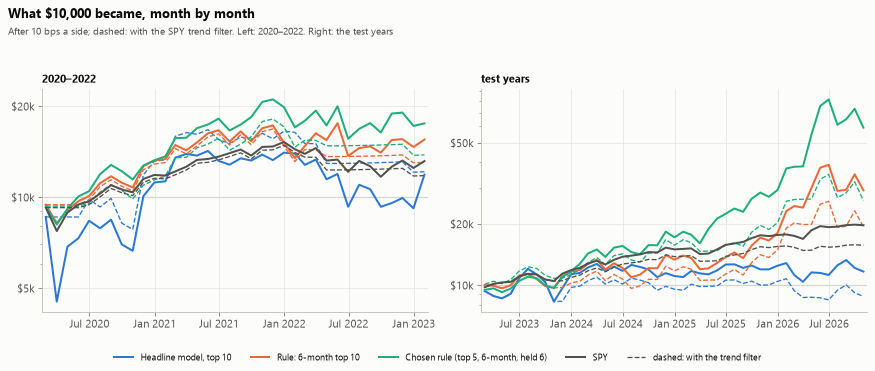

In [6]:
lines = {
    f"{headline}_top10_equal": ("Headline model, top 10", plots.SLOTS[0]),
    "mom_6m_top10_equal": ("Rule: 6-month top 10", plots.SLOTS[1]),
    "chosen_rule": ("Chosen rule (top 5, 6-month, held 6)", plots.SLOTS[2]),
    "spy": ("SPY", plots.INK_2),
}
series = rets.assign(spy=bench["spy"])
cols = [n for m in lines for n in (m, m + bt.TREND)]
shared = {p: bt.window(series[cols], a, b) for p, (a, b) in periods.items() if p != "2010–2022"}
fig = plots.paths_chart(
    {p: bt.value_paths(f) for p, f in shared.items()},
    lines,
    "What $10,000 became, month by month",
    "After 10 bps a side; dashed: with the SPY trend filter. Left: 2020–2022. Right: the test years",
    kind="value",
)
plots.save(fig, "risk_paths")

## 5. How deep and how long the bad stretches were

The fall from each strategy's previous peak. This is where the filter should help, if anywhere.

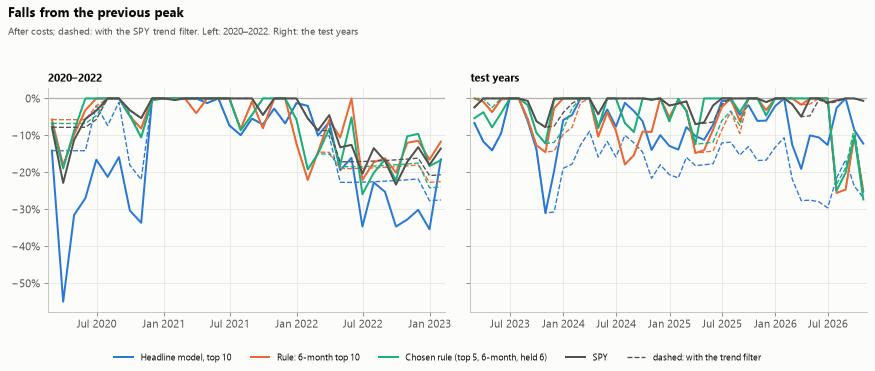

In [7]:
fig = plots.paths_chart(
    {p: bt.drawdowns(f) for p, f in shared.items()},
    lines,
    "Falls from the previous peak",
    "After costs; dashed: with the SPY trend filter. Left: 2020–2022. Right: the test years",
    kind="drawdown",
)
plots.save(fig, "risk_drawdowns")

## 6. Is the edge steady? Rolling 12-month return minus SPY's

Above zero: the strategy beat SPY over the past 12 months. Neighbouring points share 11 of their 12
months, so the line looks smoother than the evidence it carries.

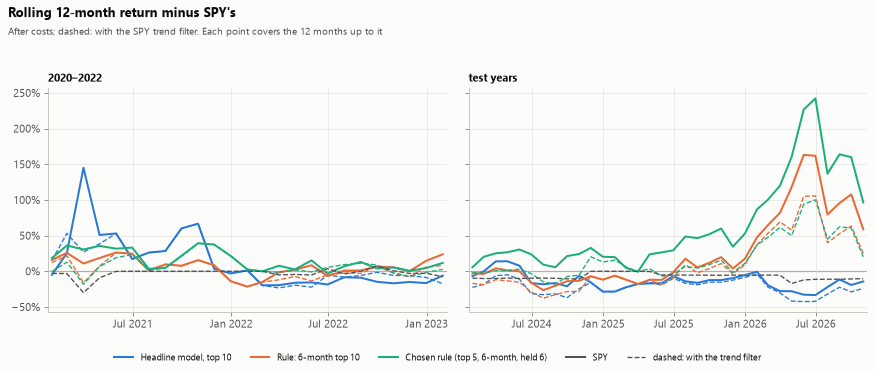

In [8]:
excess_cols = [c for c in cols if c != "spy"]
fig = plots.paths_chart(
    {p: bt.rolling_excess(f[excess_cols], bench["spy"]) for p, f in shared.items()},
    lines,
    "Rolling 12-month return minus SPY's",
    "After costs; dashed: with the SPY trend filter. Each point covers the 12 months up to it",
    kind="excess",
)
plots.save(fig, "risk_rolling")

## 7. The rules alone, from 2010

The rules need no training, so they can be followed from the start, through every downturn since
2010. The rule chosen in notebook 04 was picked on these years up to 2022, so only the part after
the dashed line is clean for it.

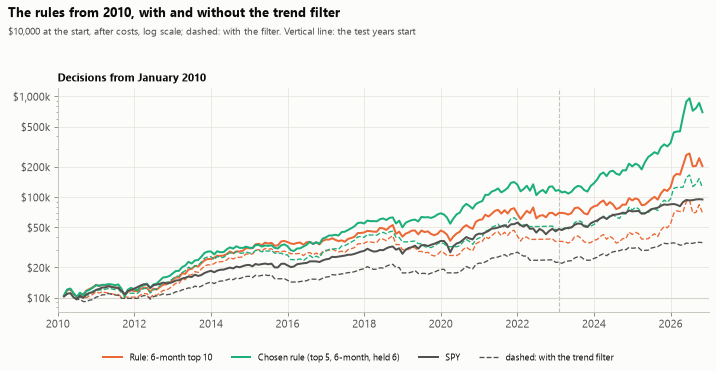

In [9]:
rule_lines = {k: lines[k] for k in ["mom_6m_top10_equal", "chosen_rule", "spy"]}
rule_cols = [n for m in rule_lines for n in (m, m + bt.TREND)]
long = bt.window(series[rule_cols], config.SPLIT["train"][0]).dropna()
fig = plots.paths_chart(
    {"Decisions from January 2010": bt.value_paths(long)},
    rule_lines,
    "The rules from 2010, with and without the trend filter",
    "$10,000 at the start, after costs, log scale; dashed: with the filter. Vertical line: the test years start",
    kind="value",
    mark=config.RULE_CHECK_FROM,
)
plots.save(fig, "risk_rules_2010")

The same rules over the whole period, as numbers:

In [10]:
long_table = bt.strategy_table(rets, costs, bench, rf, config.SPLIT["train"][0])
long_table.loc[rule_cols, ["end_value", "cagr", "volatility", "sharpe", "max_drawdown"]]

,end_value,cagr,volatility,sharpe,max_drawdown
name,,,,,
mom_6m_top10_equal,"202,176.9101",0.1966,0.2569,0.7716,-0.3027
mom_6m_top10_equal_trend,"69,824.0026",0.1230,0.2269,0.5581,-0.3702
chosen_rule,"693,341.3541",0.2880,0.2890,0.9705,-0.2733
chosen_rule_trend,"122,741.6627",0.1615,0.2193,0.7249,-0.3114
spy,"94,326.7206",0.1434,0.1481,0.8804,-0.2331
spy_trend,"35,198.0590",0.0780,0.1138,0.5845,-0.2265


## 8. What this means

- **The trend filter lowered the Sharpe ratio of SPY and of every pre-declared strategy, in every
  period.**
  - Over 2010–2026, filtered SPY turned $10,000 into $35,198, against $94,327 for SPY held
    throughout: 7.8% a year against 14.3%, and a Sharpe ratio of 0.58 against 0.88.
  - The filter was out of the market at 31 of 201 decisions. In exactly those months SPY rose 3.5% on
    average, against 0.8% in the months it was in. It kept selling after a fall and missing the sharp
    rebound that followed (the next month earned +15% in April 2020, +10% in January 2019, +9% in July
    2022).
- **It made the worst falls shallower only where the falls were long.** On 2020–2022, which held
  the Covid crash and the slow 2022 decline, it cut the headline model's worst fall from −55% to −28%
  (and that model ended slightly higher with it, $12,113 against $11,858). SPY's worst fall went from
  −23% to −21%. Across all strategies, the worst falls were on average 12–14 points shallower, but the
  Sharpe ratio rose for only 37–53% of them.
- **On the test years it rarely triggered, and didn't help when it did.** It was out at 4 of 45
  decisions (October 2023, March and April 2025, March 2026), each after SPY had already fallen. The
  worst falls barely changed. The Sharpe ratio rose for only 10–13% of the strategies: SPY's fell from
  1.21 to 0.80, and so did the chosen rule's.
- **From 2010, it even deepened the rules' worst falls** (the 6-month rule: −30% → −37%; the chosen
  rule: −27% → −31%), because it sold low and bought back higher. That's the known weakness of trend
  filters when downturns recover quickly, as most did after 2010.
- **The paths show when the rules' test-year lead came.** The 6-month rule ran roughly level with SPY
  until mid-2025. The chosen rule was ahead from 2024, but most of its lead, and the 6-month rule's,
  arrived in late 2025 and 2026, during the AI and memory-chip rally seen in notebook 04. A lead that
  arrives in one burst is a bet that paid off, not a steady edge.
- **The headline model's path is the most volatile of all.** On 2020–2022 it fell as far as −55%
  from its previous peak, against SPY's −23%.
- **For the final strategy, the filter is not adopted.** It was declared in advance and tested
  honestly, and on this data it lowers risk-adjusted returns. The comparison with SPY stays as it
  was: no pre-declared strategy clearly beats SPY per unit of risk in the test years.
- All numbers are a **preview** until the Alpha Vantage download of delisted companies is finished.
